✅ Loaded 325 courses from richku-info.json

📊 1. GPA SAMPLE SIZE CUTOFF (N) SENSITIVITY TABLE
Use this table to decide your cutoff N with your teammate:
 Min Grades (N >=) Courses Kept (All) Courses Kept (Active)  Mean GPA  Std Dev of Mean GPA  Min GPA  Max GPA Mean A-Range %
                 1        273 (84.0%)           167 (96.5%)     3.494                0.296     1.00     4.30          54.0%
                 3        248 (76.3%)           164 (94.8%)     3.499                0.205     2.53     4.06          54.8%
                 5        227 (69.8%)           156 (90.2%)     3.505                0.189     2.81     4.06          54.6%
                 8        200 (61.5%)           146 (84.4%)     3.497                0.180     2.81     4.00          54.4%
                10        186 (57.2%)           138 (79.8%)     3.489                0.176     2.81     3.93          53.7%
                15        152 (46.8%)           119 (68.8%)     3.498                0.175     2.81    

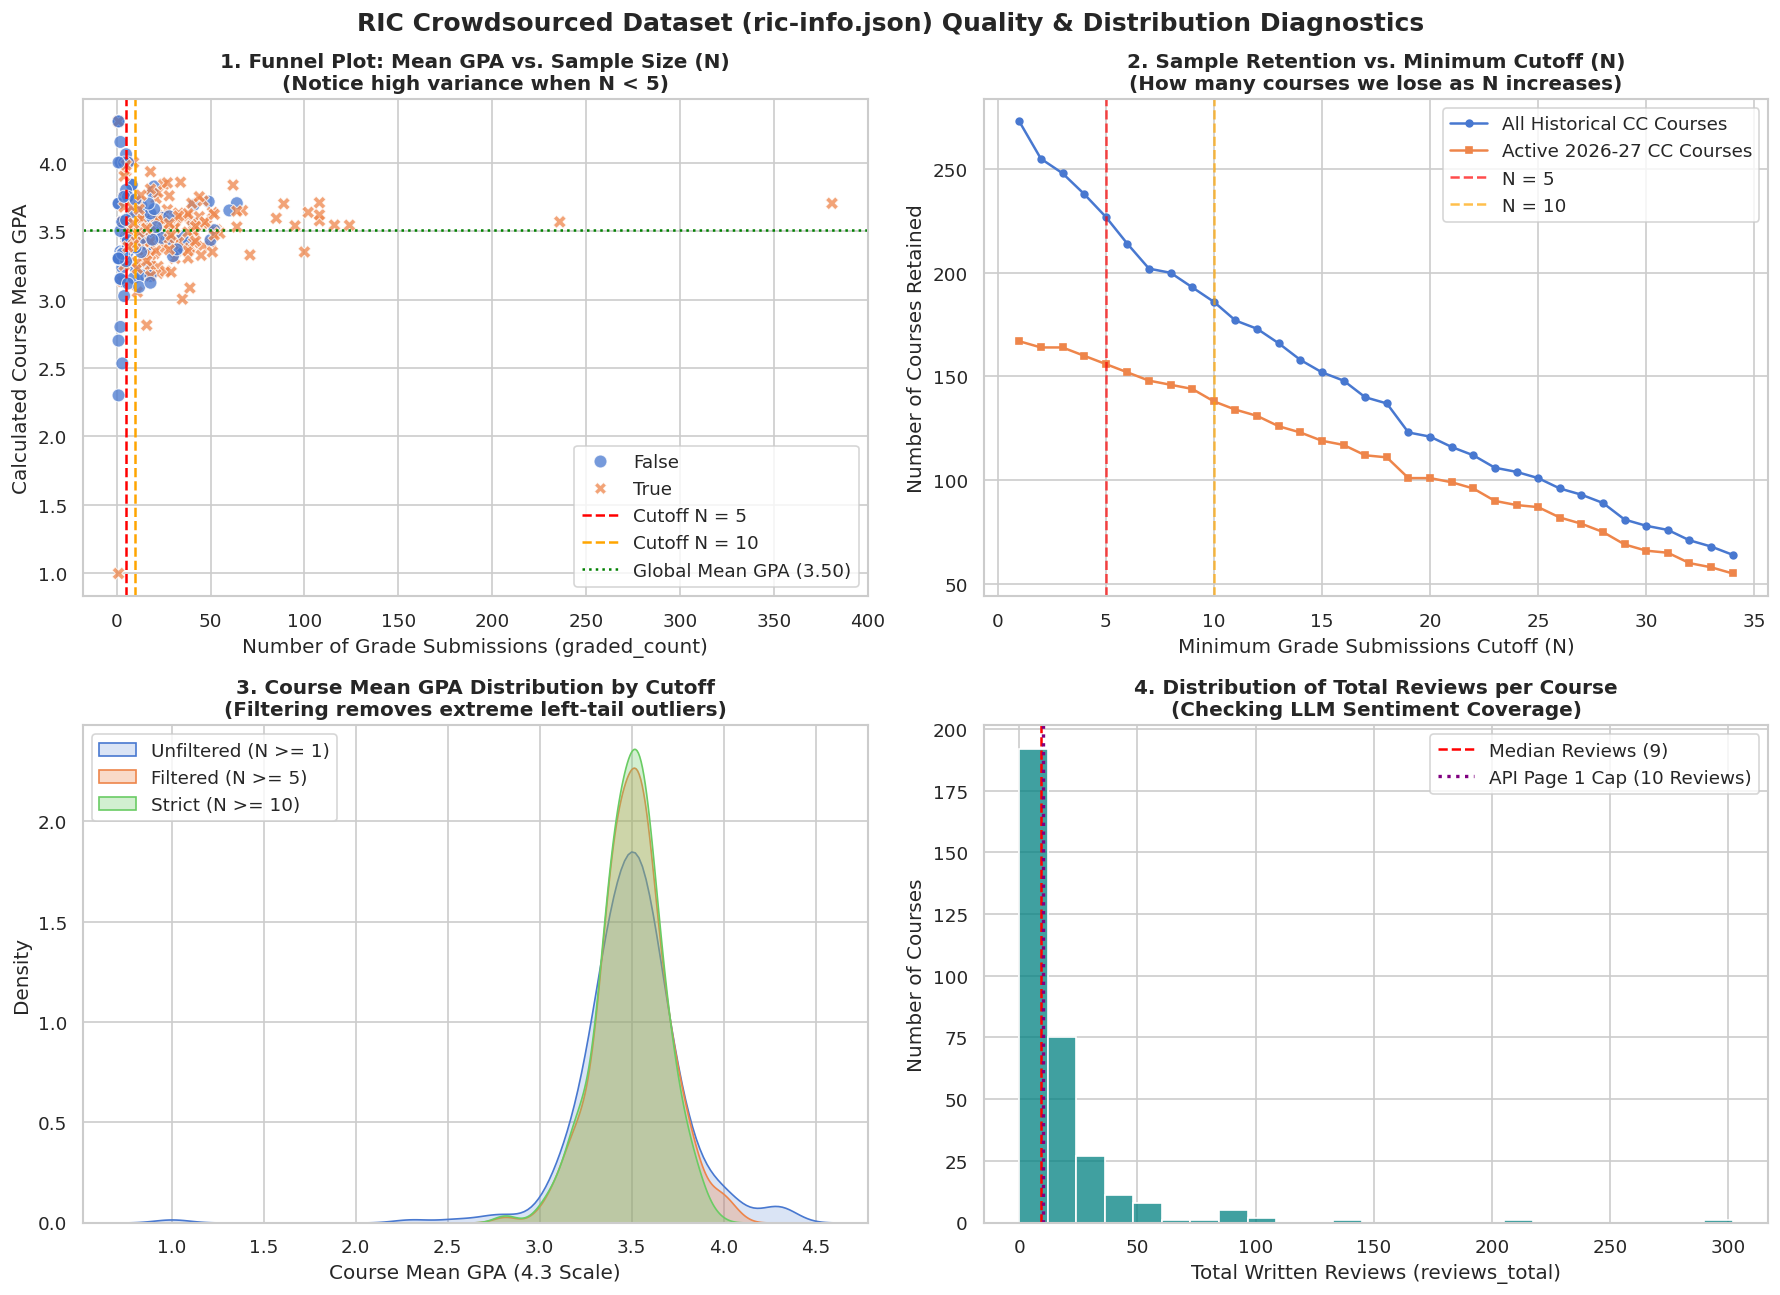

📸 Saved high-res chart to 'ric_quality_diagnostics.png' for your report!


In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for report-ready plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

# 1. Load the JSON file (checks both naming conventions)
filename = "ric-info.json"
try:
    with open(filename, "r") as f:
        ric_data = json.load(f)
except FileNotFoundError:
    filename = "richku-info.json"
    with open(filename, "r") as f:
        ric_data = json.load(f)

print(f"✅ Loaded {len(ric_data)} courses from {filename}\n")

# Official HKU 4.3 GPA Scale Mapping
GPA_WEIGHTS = {
    "grade_a_plus": 4.3,
    "grade_a": 4.0,
    "grade_a_minus": 3.7,
    "grade_b_plus": 3.3,
    "grade_b": 3.0,
    "grade_b_minus": 2.7,
    "grade_c_plus": 2.3,
    "grade_c": 2.0,
    "grade_c_minus": 1.7,
    "grade_d_plus": 1.3,
    "grade_d": 1.0,
    "grade_d_minus": 0.7,  # Rarely used at HKU, included if in schema
    "grade_fail": 0.0
}

course_rows = []
review_rows = []

for code, data in ric_data.items():
    if code.startswith("CCAI"):  # Ensure CCAI is ignored
        continue

    c_info = data.get("course_info") or data.get("search_summary") or {}
    reviews = data.get("reviews") or []

    # --- A. Calculate Grade & GPA Statistics ---
    total_gpa_points = 0.0
    graded_count = 0
    a_range_count = 0
    b_range_count = 0
    fail_count = c_info.get("grade_fail", 0) or 0

    for grade_key, weight in GPA_WEIGHTS.items():
        cnt = c_info.get(grade_key, 0) or 0
        total_gpa_points += cnt * weight
        graded_count += cnt
        if grade_key in ["grade_a_plus", "grade_a", "grade_a_minus"]:
            a_range_count += cnt
        elif grade_key in ["grade_b_plus", "grade_b", "grade_b_minus"]:
            b_range_count += cnt

    pass_count = c_info.get("grade_pass", 0) or 0
    total_submissions = graded_count + pass_count

    mean_gpa = (total_gpa_points / graded_count) if graded_count > 0 else np.nan
    a_range_ratio = (a_range_count / graded_count) if graded_count > 0 else np.nan
    fail_ratio = (fail_count / graded_count) if graded_count > 0 else np.nan

    # Calculate within-course GPA standard deviation (measures polarization)
    if graded_count > 1:
        variance = sum((c_info.get(k, 0) or 0) * ((w - mean_gpa) ** 2) for k, w in GPA_WEIGHTS.items()) / (graded_count - 1)
        std_gpa = np.sqrt(variance)
    else:
        std_gpa = np.nan

    # --- B. Course Likes, Dislikes & Active Status ---
    likes = c_info.get("liked_count", 0) or 0
    dislikes = c_info.get("disliked_count", 0) or 0
    rev_total = data.get("reviews_total", c_info.get("reviewed_count", len(reviews))) or 0

    subclasses = c_info.get("subclasses") or []
    is_active = any(sub.get("is_active", False) for sub in subclasses) if subclasses else False

    # --- C. Review-Level Statistics ---
    rev_likes_list = []
    for r in reviews:
        r_likes = r.get("liked_count", 0) or 0
        rev_likes_list.append(r_likes)
        review_rows.append({
            "course_code": code,
            "year_taken": r.get("year_taken", "Unknown"),
            "sem_taken": r.get("sem_taken", "Unknown"),
            "liked_count": r_likes,
            "has_instructor": bool(r.get("instructor", "").strip()),
            "text_len_words": len((r.get("translated_content") or r.get("content") or "").split())
        })

    course_rows.append({
        "course_code": code,
        "aoi": code[:4],
        "is_active": is_active,
        "graded_count": graded_count,
        "total_submissions": total_submissions,
        "mean_gpa": mean_gpa,
        "std_gpa": std_gpa,
        "a_range_ratio": a_range_ratio,
        "fail_count": fail_count,
        "fail_ratio": fail_ratio,
        "course_likes": likes,
        "course_dislikes": dislikes,
        "course_total_votes": likes + dislikes,
        "reviews_total": rev_total,
        "reviews_fetched": len(reviews),
        "review_likes_sum": sum(rev_likes_list),
        "review_likes_max": max(rev_likes_list) if rev_likes_list else 0
    })

df_ric = pd.DataFrame(course_rows)
df_rev = pd.DataFrame(review_rows)

# ==============================================================================
# 1. SENSITIVITY ANALYSIS: MINIMUM SAMPLE SIZE CUTOFF (N) FOR GPA
# ==============================================================================
print("="*80)
print("📊 1. GPA SAMPLE SIZE CUTOFF (N) SENSITIVITY TABLE")
print("="*80)
print("Use this table to decide your cutoff N with your teammate:")

cutoffs = [1, 3, 5, 8, 10, 15, 20, 30]
cutoff_stats = []

for n in cutoffs:
    sub = df_ric[df_ric["graded_count"] >= n]
    sub_active = sub[sub["is_active"] == True]
    cutoff_stats.append({
        "Min Grades (N >=)": n,
        "Courses Kept (All)": f"{len(sub)} ({len(sub)/len(df_ric)*100:.1f}%)",
        "Courses Kept (Active)": f"{len(sub_active)} ({len(sub_active)/max(1, df_ric['is_active'].sum())*100:.1f}%)",
        "Mean GPA": round(sub["mean_gpa"].mean(), 3),
        "Std Dev of Mean GPA": round(sub["mean_gpa"].std(), 3),
        "Min GPA": round(sub["mean_gpa"].min(), 2),
        "Max GPA": round(sub["mean_gpa"].max(), 2),
        "Mean A-Range %": f"{sub['a_range_ratio'].mean()*100:.1f}%"
    })

df_cutoff = pd.DataFrame(cutoff_stats)
print(df_cutoff.to_string(index=False))

print("\n💡 Tip: Look at where 'Std Dev of Mean GPA' and 'Min GPA' stabilize!")
print("Courses with N < 5 often have extreme Min/Max GPAs (e.g., 1.8 or 4.3) due to a single troll/outlier vote.\n")

# Inspect suspicious low-sample outlier courses (e.g. N between 1 and 5 with Fail grades or extreme GPA)
print("🔍 Examples of noisy low-sample courses (1 <= N < 5) with extreme GPAs or Fails:")
noisy_examples = df_ric[(df_ric["graded_count"] >= 1) & (df_ric["graded_count"] < 5)].sort_values(by="mean_gpa")
print(noisy_examples[["course_code", "is_active", "graded_count", "mean_gpa", "fail_count", "a_range_ratio"]].head(8).to_string(index=False))
print()

# ==============================================================================
# 2. OVERALL GPA & GRADE DISTRIBUTION STATISTICS
# ==============================================================================
print("="*80)
print("🎓 2. OVERALL GPA STATISTICS & AREA OF INQUIRY BREAKDOWN (For N >= 5)")
print("="*80)
reliable_gpa = df_ric[df_ric["graded_count"] >= 5]
print(reliable_gpa[["graded_count", "mean_gpa", "std_gpa", "a_range_ratio"]].describe().round(3))

print("\nBreakdown by Area of Inquiry (N >= 5):")
aoi_summary = reliable_gpa.groupby("aoi").agg(
    course_count=("course_code", "count"),
    avg_graded_sample=("graded_count", "mean"),
    avg_gpa=("mean_gpa", "mean"),
    median_gpa=("mean_gpa", "median"),
    avg_a_range_pct=("a_range_ratio", lambda x: x.mean() * 100)
).round(3)
print(aoi_summary)
print()

# ==============================================================================
# 3. LIKES / DISLIKES & REVIEWS STATISTICS
# ==============================================================================
print("="*80)
print("👍 3. COURSE LIKES/DISLIKES vs. REVIEW UP-VOTES STATISTICS")
print("="*80)
print(f"Courses with >0 Course-Level Likes/Dislikes: {(df_ric['course_total_votes'] > 0).sum()} / {len(df_ric)} ({(df_ric['course_total_votes'] > 0).mean()*100:.1f}%)")
print(f"Courses with >0 Written Reviews:             {(df_ric['reviews_total'] > 0).sum()} / {len(df_ric)} ({(df_ric['reviews_total'] > 0).mean()*100:.1f}%)")
print(f"Courses with >=5 Written Reviews:            {(df_ric['reviews_total'] >= 5).sum()} / {len(df_ric)} ({(df_ric['reviews_total'] >= 5).mean()*100:.1f}%)")
print(f"Courses where total reviews > 10 (Paginated):{(df_ric['reviews_total'] > 10).sum()} / {len(df_ric)} (Fetched top 10)")

print("\nCourse-Level Votes & Review Counts Summary:")
print(df_ric[["course_likes", "course_dislikes", "reviews_total", "reviews_fetched", "review_likes_sum"]].describe().round(2))

if not df_rev.empty:
    print("\nWritten Review-Level Statistics (Total Fetched Reviews =", len(df_rev), "):")
    print(df_rev[["liked_count", "text_len_words"]].describe().round(2))
    print("\nReviews Distribution by Academic Year Taken:")
    print(df_rev["year_taken"].value_counts())
print()

# ==============================================================================
# 4. GENERATE 4 DIAGNOSTIC PLOTS FOR CHECKPOINT REPORT
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("RIC Crowdsourced Dataset (ric-info.json) Quality & Distribution Diagnostics", fontsize=15, fontweight="bold")

# Plot 1: Funnel Plot (Mean GPA vs Graded Sample Size N) - Crucial for justifying Cutoff N!
ax1 = axes[0, 0]
valid_g = df_ric[df_ric["graded_count"] > 0]
sns.scatterplot(
    data=valid_g, x="graded_count", y="mean_gpa",
    hue="is_active", style="is_active", alpha=0.75, s=60, ax=ax1
)
ax1.axvline(5, color="red", linestyle="--", linewidth=1.5, label="Cutoff N = 5")
ax1.axvline(10, color="orange", linestyle="--", linewidth=1.5, label="Cutoff N = 10")
ax1.axhline(reliable_gpa["mean_gpa"].mean(), color="green", linestyle=":", label=f"Global Mean GPA ({reliable_gpa['mean_gpa'].mean():.2f})")
ax1.set_title("1. Funnel Plot: Mean GPA vs. Sample Size (N)\n(Notice high variance when N < 5)", fontweight="bold")
ax1.set_xlabel("Number of Grade Submissions (graded_count)")
ax1.set_ylabel("Calculated Course Mean GPA")
ax1.legend(loc="lower right")

# Plot 2: Trade-off Curve (Coverage vs. Cutoff N)
ax2 = axes[0, 1]
n_range = range(1, 35)
all_kept = [len(df_ric[df_ric["graded_count"] >= n]) for n in n_range]
active_kept = [len(df_ric[(df_ric["graded_count"] >= n) & (df_ric["is_active"] == True)]) for n in n_range]
ax2.plot(n_range, all_kept, marker="o", markersize=4, label="All Historical CC Courses")
ax2.plot(n_range, active_kept, marker="s", markersize=4, label="Active 2026-27 CC Courses")
ax2.axvline(5, color="red", linestyle="--", alpha=0.7, label="N = 5")
ax2.axvline(10, color="orange", linestyle="--", alpha=0.7, label="N = 10")
ax2.set_title("2. Sample Retention vs. Minimum Cutoff (N)\n(How many courses we lose as N increases)", fontweight="bold")
ax2.set_xlabel("Minimum Grade Submissions Cutoff (N)")
ax2.set_ylabel("Number of Courses Retained")
ax2.legend()

# Plot 3: GPA Distribution Before vs After Filtering (N >= 1 vs N >= 5 vs N >= 10)
ax3 = axes[1, 0]
sns.kdeplot(df_ric[df_ric["graded_count"] >= 1]["mean_gpa"], label="Unfiltered (N >= 1)", ax=ax3, fill=True, alpha=0.2)
sns.kdeplot(df_ric[df_ric["graded_count"] >= 5]["mean_gpa"], label="Filtered (N >= 5)", ax=ax3, fill=True, alpha=0.3)
sns.kdeplot(df_ric[df_ric["graded_count"] >= 10]["mean_gpa"], label="Strict (N >= 10)", ax=ax3, fill=True, alpha=0.3)
ax3.set_title("3. Course Mean GPA Distribution by Cutoff\n(Filtering removes extreme left-tail outliers)", fontweight="bold")
ax3.set_xlabel("Course Mean GPA (4.3 Scale)")
ax3.set_ylabel("Density")
ax3.legend()

# Plot 4: Written Reviews Count Distribution & Engagement
ax4 = axes[1, 1]
sns.histplot(df_ric["reviews_total"], bins=25, kde=False, color="teal", ax=ax4)
ax4.axvline(df_ric["reviews_total"].median(), color="red", linestyle="--", label=f"Median Reviews ({df_ric['reviews_total'].median():.0f})")
ax4.axvline(10, color="purple", linestyle=":", linewidth=2, label="API Page 1 Cap (10 Reviews)")
ax4.set_title("4. Distribution of Total Reviews per Course\n(Checking LLM Sentiment Coverage)", fontweight="bold")
ax4.set_xlabel("Total Written Reviews (reviews_total)")
ax4.set_ylabel("Number of Courses")
ax4.legend()

plt.tight_layout()
plt.savefig("ric_quality_diagnostics.png", dpi=300)
plt.show()
print("📸 Saved high-res chart to 'ric_quality_diagnostics.png' for your report!")